# FineWeb-2: русский подкорпус `rus_Cyrl`

Первый кандидат на общеязыковую базу для модели 50–100M.

Полный отфильтрованный подкорпус — около **699 млн документов**, **589 млрд слов**, **1.81 ТБ**. Отдельной маленькой версии нет, поэтому ниже читается только поток: 12 шардов, равномерно разнесённых по списку файлов, и в каждом один случайный parquet row group (1000 документов, примерно 9 МБ). Полный шард около 5 ГБ не скачивается.

Сид `22`. Повторный запуск ячейки загрузки берёт уже сохранённый файл. Сплит `test` не используем.

In [1]:
import json
import re
from collections import Counter
from pathlib import Path
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import HfApi
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "environment.yml").exists():
    ROOT = ROOT.parent

OUT_DIR = ROOT / "data" / "fineweb2" / "rus_Cyrl"
SAMPLE_PATH = OUT_DIR / "sample_seed22_12k.parquet"
REPO = "HuggingFaceFW/fineweb-2"
REMOTE_DIR = "data/rus_Cyrl/train"
N_SHARDS = 12
SEED = 22

STOPWORDS = {
    "в", "и", "на", "с", "года", "по", "году", "из", "был", "к", "не", "от",
    "что", "за", "для", "его", "как", "а", "он", "также", "до", "после",
}
WORD_RE = re.compile(r"\S+")
WORD_CLEAN_RE = re.compile(r"[^\w]+", re.UNICODE)
TERMINAL_PUNCT = set(".!?…:;")

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Загрузка выборки

Row group читается по HTTP range request. Метрики ниже считаются локально и не повторяют код фильтра FineWeb байт в байт: пороги русского конфига (`language_score` ≥ 0.9, повтор строк ≤ 0.322, пунктуация строк ≥ 0.231, переводы строки ≤ 0.139) уже применены авторами.

In [2]:
def list_train_files():
    entries = HfApi().list_repo_tree(
        REPO, repo_type="dataset", path_in_repo=REMOTE_DIR, recursive=False
    )
    return sorted(item.path for item in entries if item.path.endswith(".parquet"))


def pick_files(files, n_shards):
    indexes = [round(i * (len(files) - 1) / (n_shards - 1)) for i in range(n_shards)]
    return [files[i] for i in dict.fromkeys(indexes)]


def text_metrics(text):
    words = WORD_RE.findall(text)
    n_words = len(words)
    n_chars = len(text)
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    n_lines = len(lines)

    n_cyr = n_lat = n_letters = 0
    for ch in text:
        if not ch.isalpha():
            continue
        n_letters += 1
        o = ord(ch)
        if 0x0400 <= o <= 0x04FF or ch in "ёЁ":
            n_cyr += 1
        elif "A" <= ch <= "Z" or "a" <= ch <= "z":
            n_lat += 1

    word_lens = []
    n_non_alpha = 0
    n_stop = 0
    for word in words:
        cleaned = WORD_CLEAN_RE.sub("", word).lower()
        if not cleaned or not any(ch.isalpha() for ch in cleaned):
            n_non_alpha += 1
            continue
        word_lens.append(len(cleaned))
        if cleaned in STOPWORDS:
            n_stop += 1

    if lines:
        counts = Counter(lines)
        line_chars = sum(len(line) * count for line, count in counts.items())
        dup_chars = sum(len(line) * count for line, count in counts.items() if count > 1)
        dup_line_char_frac = dup_chars / line_chars if line_chars else 0.0
        punct_line_frac = sum(line[-1] in TERMINAL_PUNCT for line in lines) / n_lines
    else:
        dup_line_char_frac = 0.0
        punct_line_frac = 0.0

    return {
        "n_chars": n_chars,
        "n_words": n_words,
        "n_lines": n_lines,
        "cyr_ratio": (n_cyr / n_letters) if n_letters else 0.0,
        "lat_ratio": (n_lat / n_letters) if n_letters else 0.0,
        "avg_word_len": float(np.mean(word_lens)) if word_lens else 0.0,
        "non_alpha_word_ratio": (n_non_alpha / n_words) if n_words else 0.0,
        "newline_ratio": (text.count("\n") / n_chars) if n_chars else 0.0,
        "dup_line_char_frac": dup_line_char_frac,
        "punct_line_frac": punct_line_frac,
        "stopword_ratio": (n_stop / n_words) if n_words else 0.0,
    }


def domain_of(url):
    host = urlparse(url).netloc.lower()
    return host[4:] if host.startswith("www.") else host or "(none)"


if SAMPLE_PATH.exists():
    df = pd.read_parquet(SAMPLE_PATH)
    print(f"loaded {SAMPLE_PATH.relative_to(ROOT)}  docs={len(df):,}")
else:
    files = list_train_files()
    chosen = pick_files(files, N_SHARDS)
    rng = np.random.default_rng(SEED)
    frames = []
    print(f"train shards: {len(files):,}. reading {len(chosen)} row groups")
    for path in chosen:
        remote = f"hf://datasets/{REPO}/{path}"
        pf = pq.ParquetFile(remote)
        row_group = int(rng.integers(0, pf.num_row_groups))
        print(f"  {path}  row_group={row_group}/{pf.num_row_groups}", flush=True)
        frame = pf.read_row_group(row_group).to_pandas()
        frame["shard"] = path
        frame["row_group"] = row_group
        frames.append(frame)
    df = pd.concat(frames, ignore_index=True)
    metrics = df["text"].map(text_metrics).apply(pd.Series)
    df = pd.concat([df, metrics], axis=1)
    df["domain"] = df["url"].map(domain_of)
    df["strict_keep"] = (
        (df["cyr_ratio"] >= 0.90)
        & (df["n_words"] >= 80)
        & (df["newline_ratio"] <= 0.08)
        & (df["dup_line_char_frac"] <= 0.15)
        & (df["punct_line_frac"] >= 0.20)
        & (df["language_score"] >= 0.95)
    )
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    df.to_parquet(SAMPLE_PATH, index=False)
    print(f"saved {SAMPLE_PATH.relative_to(ROOT)}  docs={len(df):,}")

print(
    f"words={df['n_words'].sum():,.0f}  chars={df['n_chars'].sum():,.0f}  "
    f"domains={df['domain'].nunique():,}"
)

train shards: 440. reading 12 row groups


  data/rus_Cyrl/train/000_00000.parquet  row_group=1399/1815


  data/rus_Cyrl/train/000_00040.parquet  row_group=654/1787


  data/rus_Cyrl/train/001_00000.parquet  row_group=1161/1760


  data/rus_Cyrl/train/001_00040.parquet  row_group=346/1737


  data/rus_Cyrl/train/002_00000.parquet  row_group=1634/1731


... (4 outputs left out)

  data/rus_Cyrl/train/004_00039.parquet  row_group=746/1626


  data/rus_Cyrl/train/004_00079.parquet  row_group=194/1321


  data/rus_Cyrl/train/005_00039.parquet  row_group=445/451


saved data/fineweb2/rus_Cyrl/sample_seed22_12k.parquet  docs=12,000
words=8,449,229  chars=61,460,407  domains=9,968


## Длина документов

Короткий обрывок почти не учит синтаксис модели на 50–100M. Очень длинная страница чаще оказывается лентой или каталогом, чем связным текстом.

,p10,p25,p50,p75,p90,p99
n_chars,600,942,1815,4236,11084,51678
n_words,82,128,247,583,1518,7176


среднее: 704 слов, 5122 символов


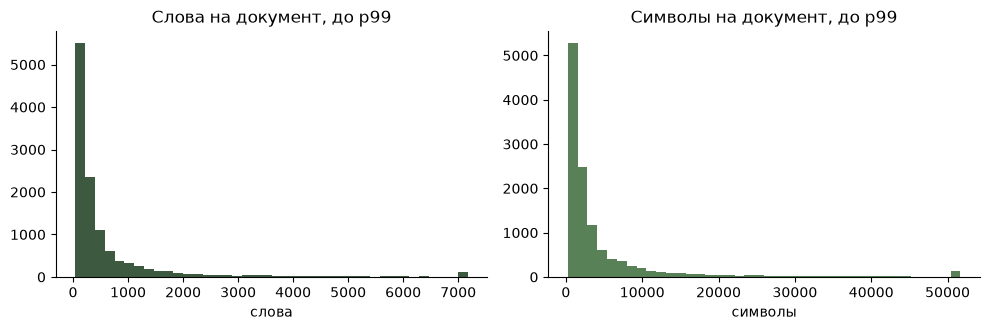

In [3]:
length = df[["n_chars", "n_words"]].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).T
length.columns = ["p10", "p25", "p50", "p75", "p90", "p99"]
display(length.round(0).astype(int))
print(f"среднее: {df['n_words'].mean():.0f} слов, {df['n_chars'].mean():.0f} символов")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(df["n_words"].clip(upper=df["n_words"].quantile(0.99)), bins=40, color="#3d5a40")
axes[0].set_title("Слова на документ, до p99")
axes[0].set_xlabel("слова")
axes[1].hist(df["n_chars"].clip(upper=df["n_chars"].quantile(0.99)), bins=40, color="#588157")
axes[1].set_title("Символы на документ, до p99")
axes[1].set_xlabel("символы")
fig.tight_layout()
plt.show()

## Язык

`language_score` — уверенность GlotLID. Доля кириллицы считается среди букв, не среди всех символов. Латиница в русском веб-тексте ожидаема: имена, марки, ссылки.

,значение
"language_score, медиана",0.999
"language_score, p10",0.998
"доля кириллицы, медиана",0.996
"доля кириллицы, p10",0.935
документы с долей кириллицы < 0.9,0.052
документы с долей латиницы > 0.2,0.012
"стоп-слова FineWeb, медиана",0.165


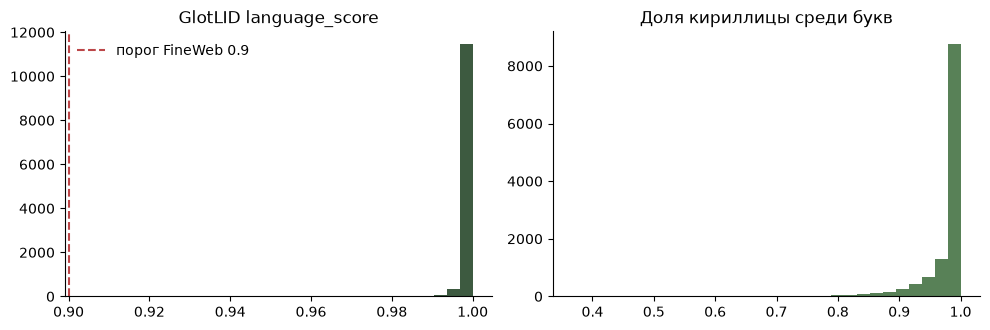

In [4]:
lang = pd.Series({
    "language_score, медиана": df["language_score"].median(),
    "language_score, p10": df["language_score"].quantile(0.1),
    "доля кириллицы, медиана": df["cyr_ratio"].median(),
    "доля кириллицы, p10": df["cyr_ratio"].quantile(0.1),
    "документы с долей кириллицы < 0.9": (df["cyr_ratio"] < 0.9).mean(),
    "документы с долей латиницы > 0.2": (df["lat_ratio"] > 0.2).mean(),
    "стоп-слова FineWeb, медиана": df["stopword_ratio"].median(),
})
display(lang.round(3).to_frame("значение"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(df["language_score"], bins=30, color="#3d5a40")
axes[0].axvline(0.9, color="#bc4749", ls="--", label="порог FineWeb 0.9")
axes[0].set_title("GlotLID language_score")
axes[0].legend(frameon=False)
axes[1].hist(df["cyr_ratio"], bins=30, color="#588157")
axes[1].set_title("Доля кириллицы среди букв")
fig.tight_layout()
plt.show()

## Остаточный шум

Для маленькой модели списки, меню и повтор строк дороже, чем для модели на миллиард параметров. `strict_keep` — наш дополнительный отсев для первого прогона, поверх уже отфильтрованного FineWeb-2:

- кириллица ≥ 0.90
- не короче 80 слов
- переводы строки ≤ 0.08
- символы в повторных строках ≤ 0.15
- строки с финальной пунктуацией ≥ 0.20
- `language_score` ≥ 0.95

,доля или значение
"переводы строки, медиана",0.005
"переводы строки, p90",0.011
"повтор строк, медиана",0.000
"повтор строк, p90",0.003
"пунктуация строк, медиана",0.786
короче 50 слов,0.002
повтор строк > 0.15,0.004
переводы строки > 0.08,0.000
strict_keep,0.858


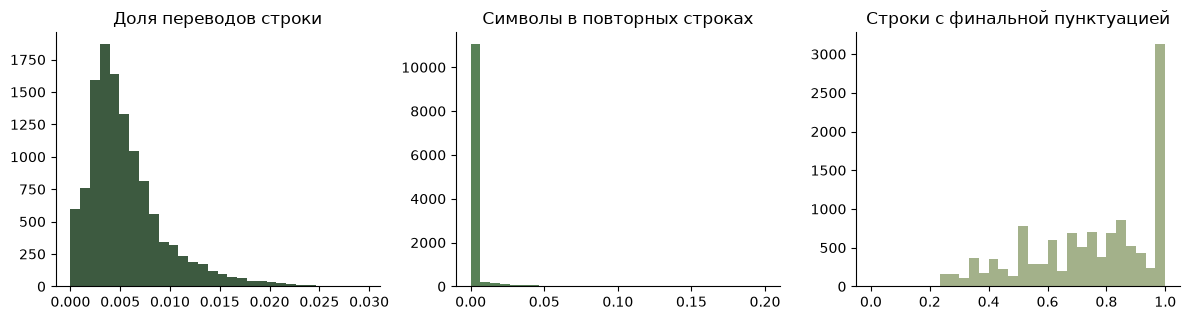

strict_keep: 10,302 / 12,000 документов


In [5]:
noise = pd.Series({
    "переводы строки, медиана": df["newline_ratio"].median(),
    "переводы строки, p90": df["newline_ratio"].quantile(0.9),
    "повтор строк, медиана": df["dup_line_char_frac"].median(),
    "повтор строк, p90": df["dup_line_char_frac"].quantile(0.9),
    "пунктуация строк, медиана": df["punct_line_frac"].median(),
    "короче 50 слов": (df["n_words"] < 50).mean(),
    "повтор строк > 0.15": (df["dup_line_char_frac"] > 0.15).mean(),
    "переводы строки > 0.08": (df["newline_ratio"] > 0.08).mean(),
    "strict_keep": df["strict_keep"].mean(),
})
display(noise.round(3).to_frame("доля или значение"))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].hist(df["newline_ratio"].clip(upper=0.2), bins=30, color="#3d5a40")
axes[0].set_title("Доля переводов строки")
axes[1].hist(df["dup_line_char_frac"], bins=30, color="#588157")
axes[1].set_title("Символы в повторных строках")
axes[2].hist(df["punct_line_frac"], bins=30, color="#a3b18a")
axes[2].set_title("Строки с финальной пунктуацией")
fig.tight_layout()
plt.show()

print(f"strict_keep: {int(df['strict_keep'].sum()):,} / {len(df):,} документов")

## Откуда текст

`minhash_cluster_size` — сколько почти-дубликатов было в кластере до того, как в корпусе оставили один документ. Значение 1 значит, что страница не имела близких копий.

доменов: 9,968
медиана minhash_cluster_size: 2
кластер размера 1: 37.5%


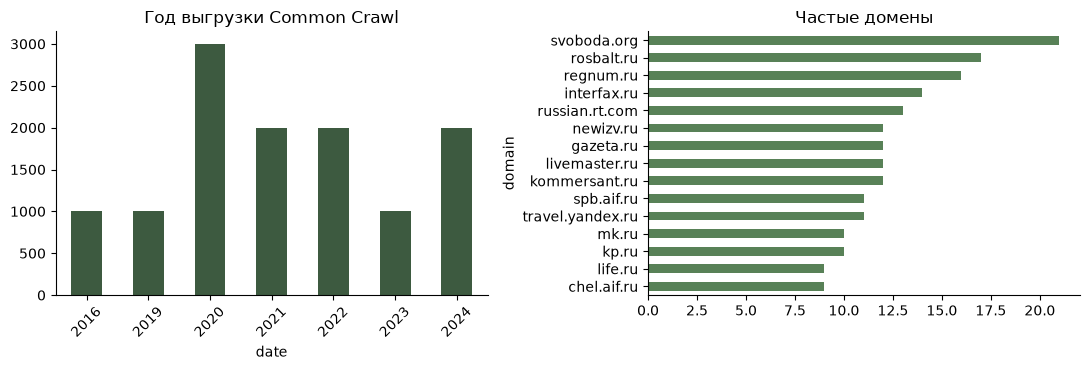

,документы
dump,
CC-MAIN-2024-18,2000
CC-MAIN-2021-25,1000
CC-MAIN-2016-50,1000
CC-MAIN-2020-10,1000
CC-MAIN-2020-05,1000
CC-MAIN-2022-27,1000
CC-MAIN-2019-47,1000
CC-MAIN-2021-43,1000
CC-MAIN-2020-45,1000


In [6]:
print(f"доменов: {df['domain'].nunique():,}")
print(f"медиана minhash_cluster_size: {df['minhash_cluster_size'].median():.0f}")
print(f"кластер размера 1: {(df['minhash_cluster_size'] == 1).mean():.1%}")

years = df["date"].str.slice(0, 4).value_counts().sort_index()
domains = df["domain"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
years.plot.bar(ax=axes[0], color="#3d5a40")
axes[0].set_title("Год выгрузки Common Crawl")
axes[0].tick_params(axis="x", labelrotation=45)
domains.sort_values().plot.barh(ax=axes[1], color="#588157")
axes[1].set_title("Частые домены")
fig.tight_layout()
plt.show()

display(df["dump"].value_counts().head(12).to_frame("документы"))

## Примеры

Типичная длина, самый короткий документ, минимум кириллицы и максимум повторных строк. Текст обрезан до 900 символов.

In [7]:
def show_doc(row, title):
    print("=" * 80)
    print(title)
    print(
        f"{row['domain']}  words={int(row['n_words'])}  cyr={row['cyr_ratio']:.2f}  "
        f"lang={row['language_score']:.3f}  dup={row['dup_line_char_frac']:.2f}  "
        f"nl={row['newline_ratio']:.3f}  keep={bool(row['strict_keep'])}"
    )
    print(row["url"])
    print(row["text"][:900])
    print()

median_words = df["n_words"].median()
typical = df.iloc[(df["n_words"] - median_words).abs().argsort()[:1]].iloc[0]
short = df.nsmallest(1, "n_words").iloc[0]
low_cyr = df.nsmallest(1, "cyr_ratio").iloc[0]
noisy = df.sort_values(["dup_line_char_frac", "newline_ratio"], ascending=False).iloc[0]

show_doc(typical, "Типичная длина")
show_doc(short, "Самый короткий в выборке")
show_doc(low_cyr, "Меньше всего кириллицы")
show_doc(noisy, "Больше всего повторных строк")

Типичная длина
puteukazatel.com  words=247  cyr=1.00  lang=0.999  dup=0.00  nl=0.005  keep=True
http://puteukazatel.com/route/71587-tomsk-novyy-urengoy.html
Маршрут Томск - Новый Уренгой на машине: расстояние, схема проезда, время в пути
Данные по маршруту Томск - Новый Уренгой предоставлены в реальном времени, актуальность карт и информации - 2019 г. География: Томск, городской округ Томск, Томская область - Новый Уренгой, Ямало-Ненецкий автономный округ, Тюменская область. Схема дороги Томск – Новый Уренгой выделена на карте синим цветом.
Расчет расстояния Томск – Новый Уренгой произведен компьютерной программой по точным спутниковым координатам дорог и населенных пунктов.
Навигатор онлайн (описание движения на автомобиле) поможет проложить маршрут из пункта отправления Томск до пункта назначения Новый Уренгой. Мы подобрали лучший маршрут по трассе со всеми подробностями и населенными пунктами на карте, просчитали затраты на топливо, расстояние и примерное время маршрута Томск - Новы

## Объём относительно модели 50–100M

Оценка токенов — символы / 2.5, если токенизатор обучался на русском. Английский BPE на кириллице сильно завышает число токенов, поэтому токенизатор для этого эксперимента нужно учить отдельно.

Chinchilla-ориентир для 50M параметров — около 1 млрд токенов, для 100M — около 2 млрд. Компактные модели часто учат дольше этого ориентира. Текущий файл такой объём не закрывает: это осмотр качества и корпус для сухого прогона, не для содержательного претрейна.

In [8]:
chars = int(df["n_chars"].sum())
words = int(df["n_words"].sum())
tokens = int(chars / 2.5)
kept = df.loc[df["strict_keep"]]
kept_tokens = int(kept["n_chars"].sum() / 2.5)

report = pd.Series({
    "документы": len(df),
    "слова": words,
    "символы": chars,
    "оценка токенов, chars/2.5": tokens,
    "токены после strict_keep": kept_tokens,
    "доля strict_keep": kept.shape[0] / len(df),
})
display(report.to_frame("выборка"))
print(
    "Для первого учебного прогона на 50–100M имеет смысл снять тем же способом "
    "сотни тысяч документов. Upsampling по весам дубликатов FineWeb-2 пока не нужен."
)

,выборка
документы,1.200000e+04
слова,8.449229e+06
символы,6.146041e+07
"оценка токенов, chars/2.5",2.458416e+07
токены после strict_keep,2.335054e+07
доля strict_keep,8.585000e-01


Для первого учебного прогона на 50–100M имеет смысл снять тем же способом сотни тысяч документов. Upsampling по весам дубликатов FineWeb-2 пока не нужен.
